In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

In [ ]:
df=pd.read_csv('/content/Salary_Data.csv')

In [ ]:
df.head()

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


In [ ]:
df.shape

(30, 2)

In [ ]:
df.describe()

,YearsExperience,Salary
count,30.000000,30.000000
mean,5.313333,76003.000000
std,2.837888,27414.429785
min,1.100000,37731.000000
25%,3.200000,56720.750000
50%,4.700000,65237.000000
75%,7.700000,100544.750000
max,10.500000,122391.000000


Text(0, 0.5, 'Salary')

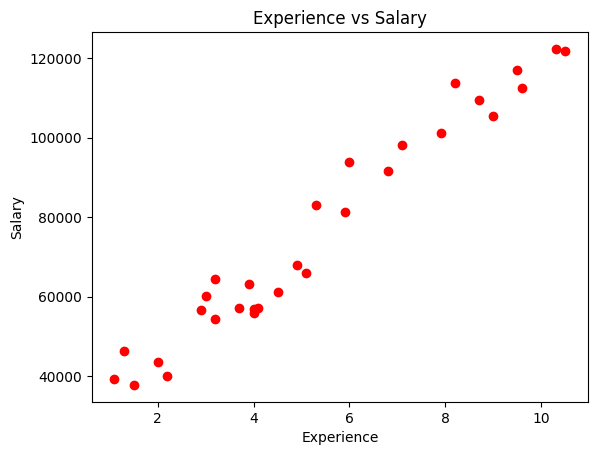

In [ ]:
plt.scatter(df['YearsExperience'],df['Salary'],color='red')
plt.title('Experience vs Salary')
plt.xlabel('Experience')
plt.ylabel('Salary')


Spliting the data into x and y

In [ ]:
X=df.drop('Salary',axis=1)
Y=df['Salary']

Spliting into training and testing

In [ ]:
xtrain,xtest,ytrain,ytest=train_test_split(X,Y,test_size=0.2,random_state=15)

In [ ]:
xtrain

,YearsExperience
1,1.3
2,1.5
29,10.5
6,3.0
3,2.0
26,9.5
25,9.0
9,3.7
4,2.2
20,6.8


In [ ]:
LR=LinearRegression()

Building the model

In [ ]:
LR

LinearRegression()

In [ ]:
LR.fit(xtrain,ytrain)

LinearRegression()

In [ ]:
ypred=LR.predict(xtest)

In [ ]:
xtest.values

array([[5.1],
       [4.5],
       [9.6],
       [7.9],
       [6. ],
       [5.9]])

In [ ]:
ypred

array([ 74275.88079276,  68602.53908487, 116825.94360193, 100751.47542958,
        82785.8933546 ,  81840.33640328])

In [ ]:
ytest.values

array([ 66029.,  61111., 112635., 101302.,  93940.,  81363.])

In [ ]:
r2=r2_score(ytest,ypred)

In [ ]:
r2

0.8697012433817218

In [ ]:
def predict(exp):
  na=np.array([exp]).reshape(1,-1)
  ans=LR.predict(na)
  return f'The predicted Salary is {int(ans)} Rs'

In [ ]:
predict(6.5)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/tmp/ipykernel_2789/449730266.py:4: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return f'The predicted Salary is {int(ans)} Rs'


'The predicted Salary is 87513 Rs'

In [ ]:
import gradio as gr
import pandas as pd
import numpy as np

def predict(exp):
    # Wrap the input in a DataFrame with the correct feature name to avoid warnings
    df_input = pd.DataFrame([[exp]], columns=['YearsExperience'])
    ans = LR.predict(df_input)
    # Use .item() to safely convert a 1D array element to a scalar
    return f'The predicted Salary is {int(ans.item())} Rs'

iface = gr.Interface(fn=predict,
                     inputs=gr.Number(label="Years of Experience"),
                     outputs=gr.Textbox(label="Predicted Salary"),
                     title="Salary Prediction Based on Years of Experience")

iface.launch(debug=True)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://1909f04ab431cfd4aa.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
